In [1]:
import numpy as np # Arrays
import pandas as pd # Dataframes
import yfinance as yf 
import matplotlib.pyplot as plt # Visualizations

# Training and Modeling 
import torch 
import torch.nn as nn 
import torch.optim as optim 

# Scaling and Metric 
from sklearn.preprocessing import StandardScaler 
from sklearn.metrics import root_mean_squared_error

In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu') # if we have a cuda supported gpu, we'll use gpu 

In [3]:
ticker = 'TSLA' 
df = yf.download(ticker, start = '2020-01-01')
feature_cols = ['Close', 'Volume', 'Open', 'High', 'Low']  # add/remove as you like
features = df[feature_cols].values  # shape (n_days, n_features)

[*********************100%***********************]  1 of 1 completed


<Axes: xlabel='Date'>

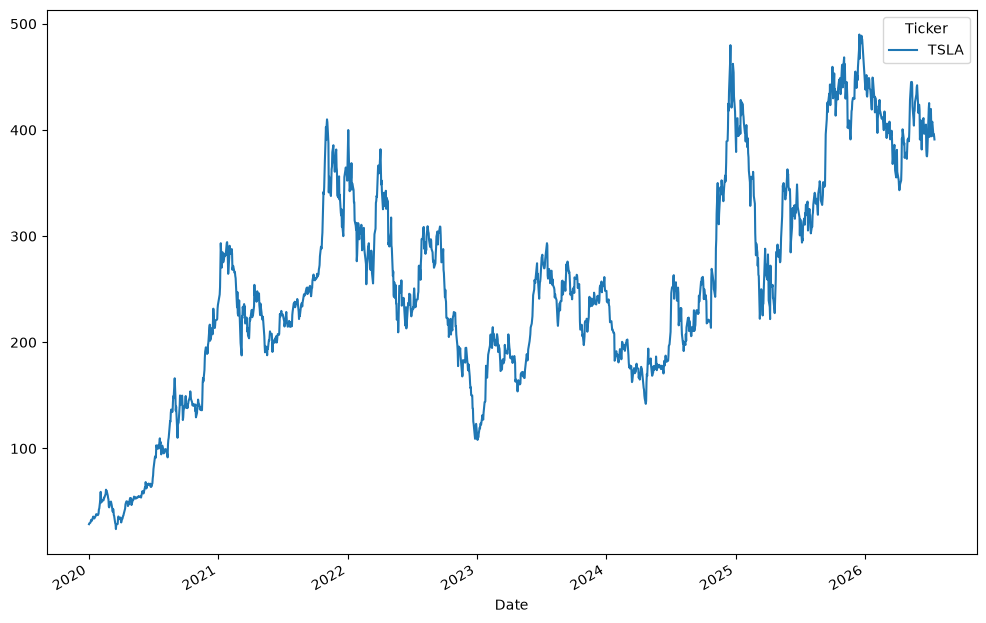

In [4]:
df.Close.plot(figsize=(12,8)) # figsize = (width, height)

In [5]:
feature_scaler = StandardScaler()
scaled_features = feature_scaler.fit_transform(features)

close_scaler = StandardScaler()
close_scaler.fit(features[:, [0]])  # index 0 = Close, assuming it's first in feature_cols




StandardScaler()

In [6]:
# Our goal is to look at any day, and see if we can predict the next data point's value 
seq_length = 30  
data = [] 

# We want to predict the 30th day given 29 days. 
for i in range(len(scaled_features) - seq_length):
    data.append(scaled_features[i:i+seq_length]) # Overlapping days and increment our bracket of days by 1. 
data = np.array(data) # Make it an array 


In [7]:
train_size = int(0.8 * len(data))

X_train = torch.from_numpy(data[:train_size, :-1, :]).type(torch.Tensor).to(device) # from numpy array -> tensor
y_train = torch.from_numpy(data[:train_size, -1, 0:1]).type(torch.Tensor).to(device)
X_test = torch.from_numpy(data[train_size:, :-1, :]).type(torch.Tensor).to(device)
y_test = torch.from_numpy(data[train_size:, -1, 0:1]).type(torch.Tensor).to(device)

In [8]:
class PredictionModel(nn.Module):

    def __init__(self, input_dim, hidden_dim, num_layers, output_dim):
        super(PredictionModel, self).__init__()

        self.num_layers = num_layers 
        self.hidden_dim = hidden_dim 

        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first = True) # I don't know what batch_first 
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim, device = device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim, device = device)

        # We will only care about out, but know that lstm gives hn and cn
        out, (hn, cn) = self.lstm(x, (h0.detach(), c0.detach()))
        out = self.fc(out[:, -1, :])

        # This will be the prediction 
        return out 
        


In [9]:
model = PredictionModel(input_dim=len(feature_cols), hidden_dim=32, num_layers=2, output_dim=1).to(device)

In [10]:
criterion = nn.MSELoss() 
optimizer = optim.Adam(model.parameters(), lr=0.01)

In [11]:
num_epochs = 200 

for i in range(num_epochs):
    y_train_pred = model(X_train)

    loss = criterion(y_train_pred, y_train) # Criterion(predicted-value, value-to-compare)

    if i % 25 == 0: 
        print(i, loss.item())

    optimizer.zero_grad() # Zero Gradients
    loss.backward() # Back Propogate the loss / mistake through weights and biases of model  
    optimizer.step() # 

0 0.7576115131378174
25 0.022613191977143288
50 0.01245669461786747
75 0.010902941226959229
100 0.009917545132339
125 0.009091933257877827
150 0.008492403663694859
175 0.008184096775949001


In [12]:
model.eval() # putting it in eval mode

y_test_pred = model(X_test)

y_train_pred = close_scaler.inverse_transform(y_train_pred.detach().cpu().numpy())
y_train = close_scaler.inverse_transform(y_train.detach().cpu().numpy())
y_test_pred = close_scaler.inverse_transform(y_test_pred.detach().cpu().numpy())
y_test = close_scaler.inverse_transform(y_test.detach().cpu().numpy())




In [13]:
train_rmse = root_mean_squared_error(y_train[:, 0], y_train_pred[:, 0])
test_rmse = root_mean_squared_error(y_test[:, 0], y_test_pred[:, 0])


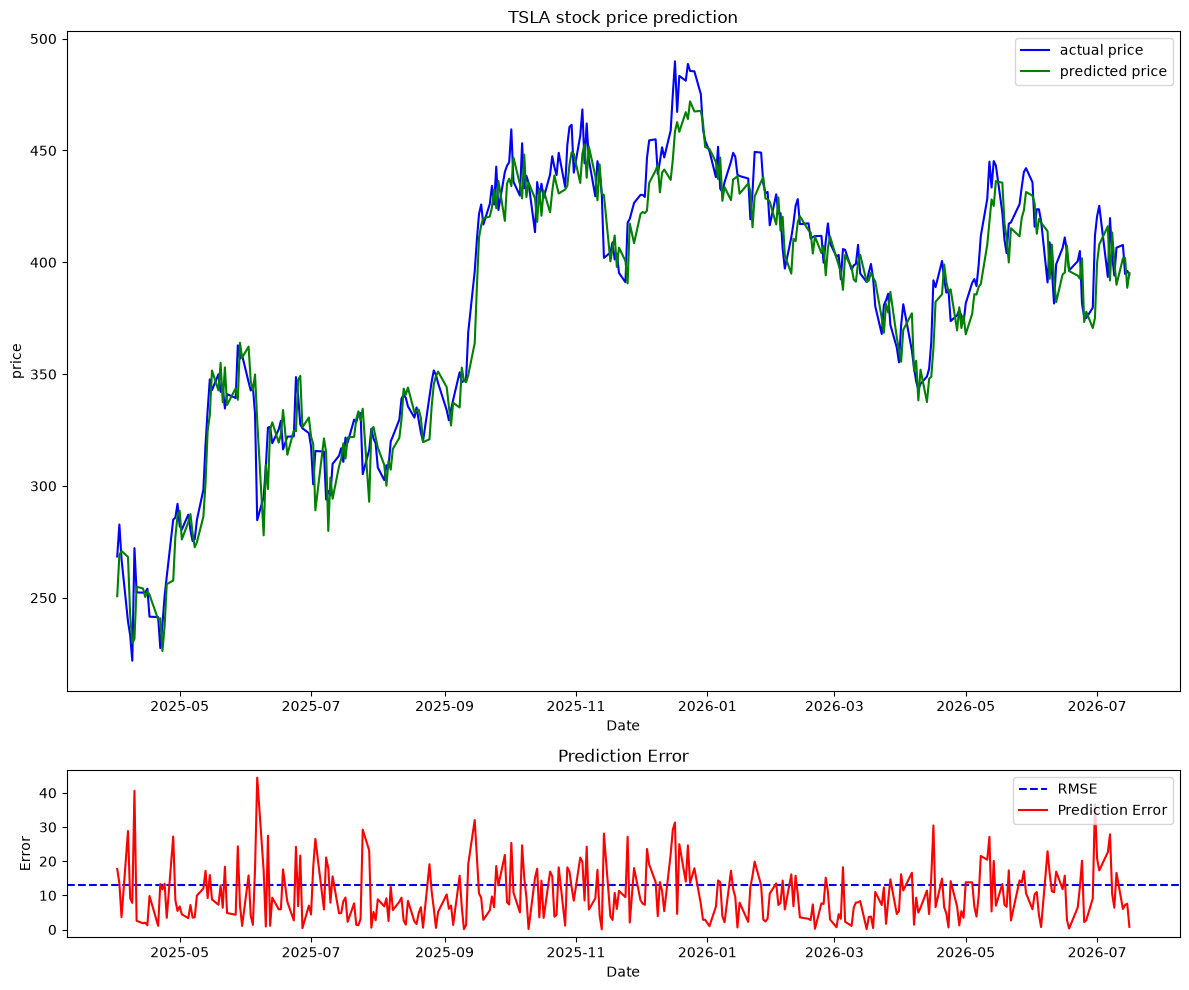

In [14]:
fig = plt.figure(figsize=(12,10))

gs = fig.add_gridspec(4,1)

ax1 = fig.add_subplot(gs[:3, 0])
ax1.plot(df.iloc[-len(y_test):].index, y_test, color = 'blue', label = 'actual price')
ax1.plot(df.iloc[-len(y_test):].index, y_test_pred, color = 'green', label = 'predicted price')
ax1.legend() 
plt.title(f"{ticker} stock price prediction")
plt.xlabel('Date')
plt.ylabel('price')

ax2 = fig.add_subplot(gs[3, 0])
ax2.axhline(test_rmse, color='blue', linestyle='--', label='RMSE')
ax2.plot(df[-len(y_test):].index, abs(y_test - y_test_pred), 'r', label = 'Prediction Error')
ax2.legend() 
plt.title(f"Prediction Error")
plt.xlabel('Date')
plt.ylabel('Error')
plt.tight_layout() 

plt.show()
